# 04 Who should get a retention offer?

Assumptions: each offer costs £10, 20% of churners who get one stay, and a saved customer is worth a 25% margin on one more year of their past spend. Only customers who would have churned can be saved.

The expected-value rule sends an offer when churn chance × success rate × margin × spend is more than the offer cost. It is compared with contacting everybody and with targeting by spend alone.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import PROCESSED_DIR
from src.evaluation import expected_value_contact, offer_gain, realized_profit

pred = pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet")
y, spend, p = pred["churn"].to_numpy(), pred["spend_365d"].to_numpy(), pred["p_churn"].to_numpy()
TRAIN_CHURN_RATE = 0.649

In [2]:
def policies(cost=10, success=0.20, margin=0.25):
    return {
        "Everybody": np.ones(len(y), bool),
        "By spend only": expected_value_contact(np.full(len(y), TRAIN_CHURN_RATE), spend, cost, success, margin),
        "Expected value": expected_value_contact(p, spend, cost, success, margin),
    }

pd.DataFrame([{"policy": name, "share contacted": f"{c.mean():.0%}",
               "profit": f"£{realized_profit(c, y, spend, 10, 0.20, 0.25):,.0f}"}
              for name, c in policies().items()])

,policy,share contacted,profit
0,Everybody,100%,"£170,875"
1,By spend only,74%,"£180,736"
2,Expected value,78%,"£183,673"


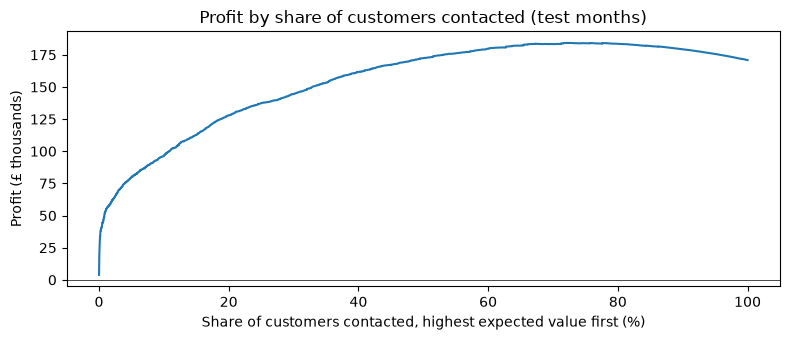

In [3]:
gain = offer_gain(y, spend, 0.20, 0.25) - 10
order = np.argsort(-(p * spend))
curve = np.cumsum(gain[order]) / 1000
share = np.arange(1, len(y) + 1) / len(y) * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(share, curve)
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("Share of customers contacted, highest expected value first (%)")
ax.set_ylabel("Profit (£ thousands)")
ax.set_title("Profit by share of customers contacted (test months)")
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "profit_curve.png")

## Different assumptions

Offer cost from £5 to £50 and success rate from 10% to 30%.

In [4]:
rows = []
for cost in (5, 10, 25, 50):
    for success in (0.10, 0.20, 0.30):
        profit = {k: realized_profit(c, y, spend, cost, success, 0.25) for k, c in policies(cost, success).items()}
        rows.append({"cost": cost, "success": success, "best policy": max(profit, key=profit.get),
                     "expected value vs everybody": f"£{profit['Expected value'] - profit['Everybody']:,.0f}"})
pd.DataFrame(rows)

,cost,success,best policy,expected value vs everybody
0,5,0.1,Expected value,"£6,399"
1,5,0.2,Expected value,"£1,833"
2,5,0.3,Expected value,£635
3,10,0.1,Expected value,"£33,388"
4,10,0.2,Expected value,"£12,798"
5,10,0.3,Expected value,"£6,916"
6,25,0.1,Expected value,"£196,658"
7,25,0.2,Expected value,"£108,852"
8,25,0.3,Expected value,"£66,020"
9,50,0.1,Expected value,"£517,067"


## Findings

In the main case the expected-value rule contacts 78% of customers and makes £183,700 over the three test months, £12,800 (7.5%) more than contacting everybody. It was the most profitable policy in all 12 scenarios, and the gap grows as offers get more expensive. These amounts depend on the assumed 20% success rate, which only a randomized test can measure: send the offer to a random half of flagged customers and compare churn after 90 days.